In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/archive (6).zip")
df

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon
...,...,...,...,...,...,...,...,...,...,...
99452,I219422,C441542,Female,45,Souvenir,5,58.65,Credit Card,21/09/2022,Kanyon
99453,I325143,C569580,Male,27,Food & Beverage,2,10.46,Cash,22/09/2021,Forum Istanbul
99454,I824010,C103292,Male,63,Food & Beverage,2,10.46,Debit Card,28/03/2021,Metrocity
99455,I702964,C800631,Male,56,Technology,4,4200.00,Cash,16/03/2021,Istinye Park


In [5]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [6]:
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


In [8]:
df.shape

(99457, 10)

In [9]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 99457
Total Columns: 10


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB


In [11]:
df.isnull().sum()

,0
invoice_no,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price,0
payment_method,0
invoice_date,0
shopping_mall,0


In [12]:
df.isnull().sum().sum()

np.int64(0)

In [129]:
# Check missing value percentage

(df.isnull().sum() / len(df)) * 100

,0
invoice_no,0.0
customer_id,0.0
gender,0.0
age,0.0
category,0.0
quantity,0.0
price,0.0
payment_method,0.0
invoice_date,0.0
shopping_mall,0.0


In [14]:
# Duplicate Values Analysis
df.duplicated().sum()

np.int64(0)

In [15]:
df[df.duplicated()]

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall


In [16]:
df["customer_id"].duplicated().sum()

np.int64(0)

In [17]:
df = df.drop_duplicates()

In [18]:
# Numerical and Categorical Column Analysis
numerical_cols = df.select_dtypes(include=np.number).columns
print(numerical_cols)

Index(['age', 'quantity', 'price'], dtype='object')


In [19]:
categorical_cols = df.select_dtypes(include="object").columns
print(categorical_cols)

Index(['invoice_no', 'customer_id', 'gender', 'category', 'payment_method',
       'invoice_date', 'shopping_mall'],
      dtype='object')


In [20]:
# Statistical summary
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


In [21]:
df.describe(include="object")

,invoice_no,customer_id,gender,category,payment_method,invoice_date,shopping_mall
count,99457,99457,99457,99457,99457,99457,99457
unique,99457,99457,2,8,3,797,10
top,I138884,C241288,Female,Clothing,Cash,24/11/2021,Mall of Istanbul
freq,1,1,59482,34487,44447,159,19943


In [22]:
price = df["price"].to_numpy()
print("Mean:", np.mean(price))
print("Median:", np.median(price))
print("Minimum:", np.min(price))
print("Maximum:", np.max(price))

Mean: 689.2563209226097
Median: 203.3
Minimum: 5.23
Maximum: 5250.0


In [23]:
# Data Cleaning: Date Conversion
print(df["invoice_date"].dtype)

object


In [24]:
df["invoice_date"] = pd.to_datetime(df["invoice_date"], dayfirst=True)

In [25]:
print(df["invoice_date"].dtype)

datetime64[ns]


In [26]:
# Extract year, month and day
df["year"] = df["invoice_date"].dt.year
df["month"] = df["invoice_date"].dt.month
df["day"] = df["invoice_date"].dt.day

In [27]:
df[["invoice_date", "year", "month", "day"]].head()

,invoice_date,year,month,day
0,2022-08-05,2022,8,5
1,2021-12-12,2021,12,12
2,2021-11-09,2021,11,9
3,2021-05-16,2021,5,16
4,2021-10-24,2021,10,24


In [28]:
# Feature Engineering: Calculate Total Spending
df["total_spending"] = df["quantity"] * df["price"]

In [29]:
df[["quantity", "price", "total_spending"]].head(10)

,quantity,price,total_spending
0,5,1500.40,7502.00
1,3,1800.51,5401.53
2,1,300.08,300.08
3,5,3000.85,15004.25
4,4,60.60,242.40
5,5,1500.40,7502.00
6,1,40.66,40.66
7,2,600.16,1200.32
8,3,900.24,2700.72
9,2,600.16,1200.32


In [30]:
total_revenue = np.sum(df["total_spending"])
print("Total Revenue:", total_revenue)

Total Revenue: 251505794.25


In [31]:
# Calculate average spending
average_spending = np.mean(df["total_spending"])
print("Average Spending:", average_spending)

Average Spending: 2528.7892682264696


In [32]:
# Find the highest transaction
highest_spending = np.max(df["total_spending"])
print("Highest Transaction:", highest_spending)

Highest Transaction: 26250.0


In [33]:
# Category-wise Spending Analysis

df["category"].unique()

array(['Clothing', 'Shoes', 'Books', 'Cosmetics', 'Food & Beverage',
       'Toys', 'Technology', 'Souvenir'], dtype=object)

In [34]:
# Count transactions by category
category_count = df["category"].value_counts()
print(category_count)

category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64


In [35]:
# Calculate category-wise total spending
category_spending = df.groupby("category")["total_spending"].sum().sort_values(ascending=False)
print(category_spending)

category
Clothing           1.139968e+08
Shoes              6.655345e+07
Technology         5.786235e+07
Cosmetics          6.792863e+06
Toys               3.980426e+06
Food & Beverage    8.495351e+05
Books              8.345529e+05
Souvenir           6.358247e+05
Name: total_spending, dtype: float64


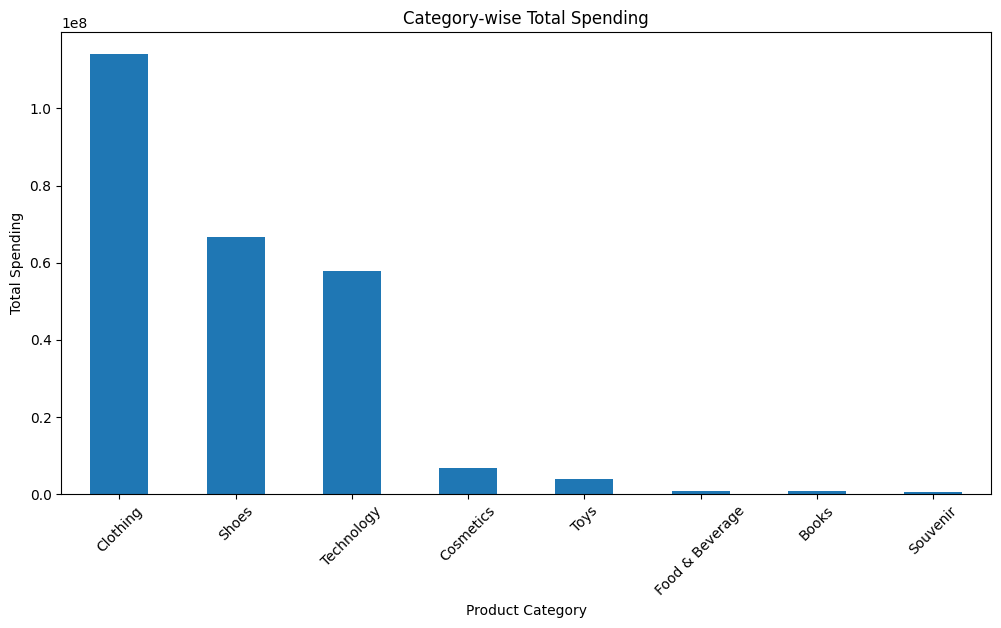

In [36]:
plt.figure(figsize=(12, 6))
category_spending.plot(kind="bar")
plt.title("Category-wise Total Spending")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

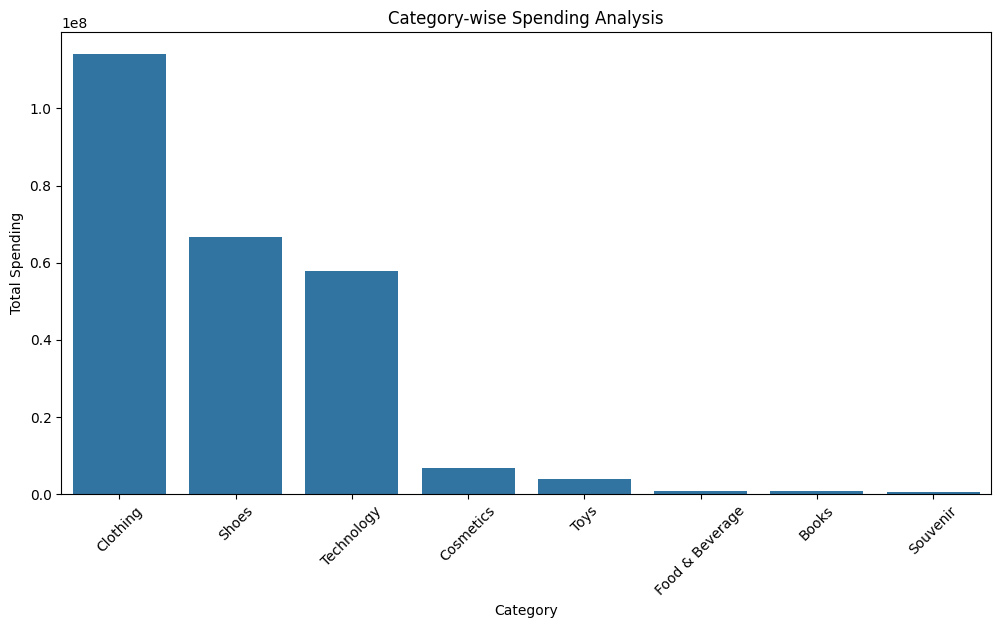

In [37]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_spending.index,
    y=category_spending.values
)
plt.title("Category-wise Spending Analysis")
plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

In [38]:
# Payment Method Analysis
df["payment_method"].unique()

array(['Credit Card', 'Debit Card', 'Cash'], dtype=object)

In [39]:
# Count transactions by payment method
payment_count = df["payment_method"].value_counts()
print(payment_count)

payment_method
Cash           44447
Credit Card    34931
Debit Card     20079
Name: count, dtype: int64


In [40]:
# Calculate total spending by payment method
payment_spending = df.groupby("payment_method")["total_spending"].sum().sort_values(ascending=False)
print(payment_spending)

payment_method
Cash           1.128322e+08
Credit Card    8.807712e+07
Debit Card     5.059643e+07
Name: total_spending, dtype: float64


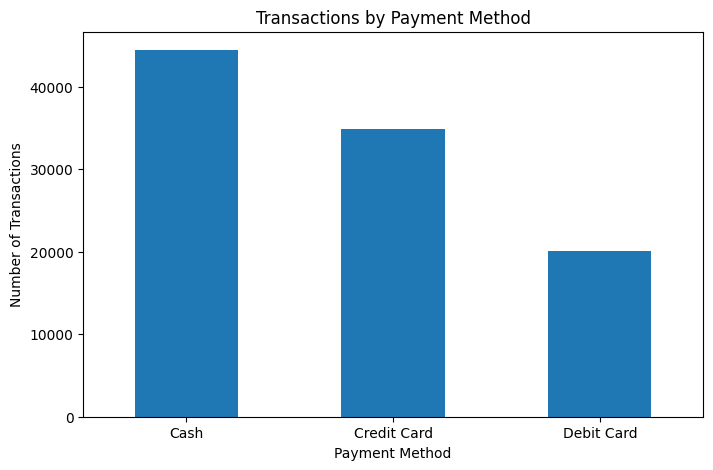

In [41]:
plt.figure(figsize=(8, 5))
payment_count.plot(kind="bar")
plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

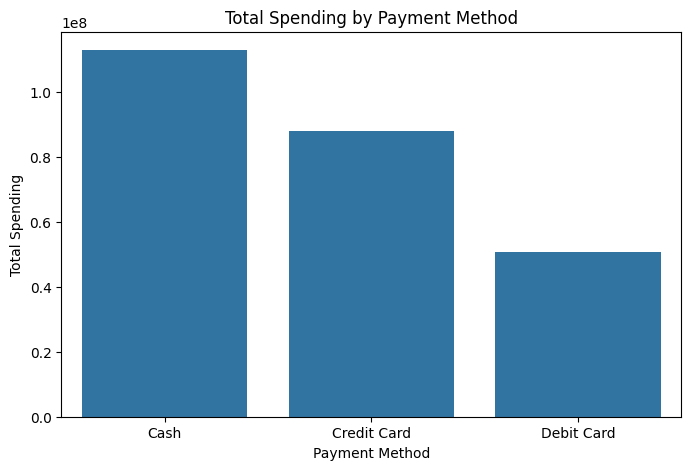

In [42]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x=payment_spending.index,
    y=payment_spending.values
)
plt.title("Total Spending by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Spending")
plt.show()

In [43]:
payment_percentage = (
    payment_spending / np.sum(payment_spending)
) * 100
print(payment_percentage)

payment_method
Cash           44.862681
Credit Card    35.019918
Debit Card     20.117400
Name: total_spending, dtype: float64


In [44]:
# Gender-wise Customer Spending Analysis
df["gender"].unique()

array(['Female', 'Male'], dtype=object)

In [45]:
# Count customers by gender
gender_count = df["gender"].value_counts()
print(gender_count)

gender
Female    59482
Male      39975
Name: count, dtype: int64


In [46]:
# Calculate gender-wise total spending
gender_spending = df.groupby("gender")["total_spending"].sum().sort_values(ascending=False)
print(gender_spending)

gender
Female    1.502071e+08
Male      1.012987e+08
Name: total_spending, dtype: float64


In [47]:
# Calculate average spending by gender
average_gender_spending = df.groupby("gender")["total_spending"].mean()
print(average_gender_spending)

gender
Female    2525.253623
Male      2534.050237
Name: total_spending, dtype: float64


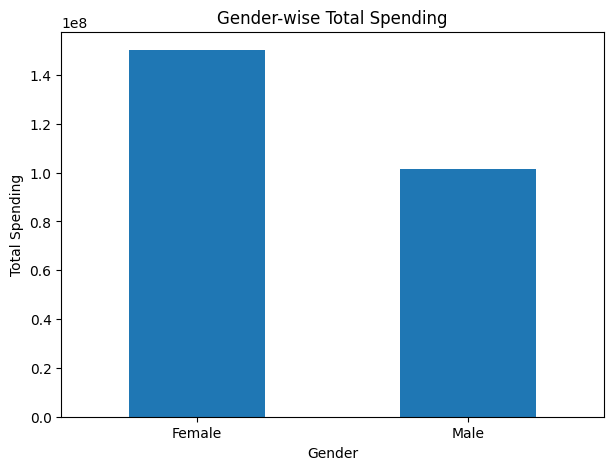

In [48]:
plt.figure(figsize=(7, 5))
gender_spending.plot(kind="bar")
plt.title("Gender-wise Total Spending")
plt.xlabel("Gender")
plt.ylabel("Total Spending")
plt.xticks(rotation=0)
plt.show()

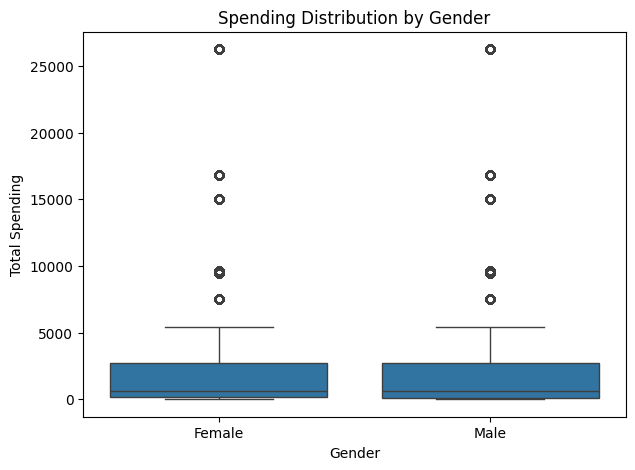

In [49]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="gender", y="total_spending")
plt.title("Spending Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Spending")
plt.show()

In [50]:
# Age-wise Customer Spending Analysis
print(df["age"].describe())

count    99457.000000
mean        43.427089
std         14.990054
min         18.000000
25%         30.000000
50%         43.000000
75%         56.000000
max         69.000000
Name: age, dtype: float64


In [51]:
# Create age groups
bins = [0, 18, 25, 35, 50, 100]
labels = ["Under 18", "18-25", "26-35", "36-50", "Above 50"]
df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)


In [52]:
# Count transactions by age group
age_count = df["age_group"].value_counts().sort_index()
print(age_count)

age_group
Under 18     1844
18-25       13515
26-35       19059
36-50       28938
Above 50    36101
Name: count, dtype: int64


In [53]:
# Calculate total spending by age group
age_spending = df.groupby(
    "age_group",
    observed=False
)["total_spending"].sum()
print(age_spending)

age_group
Under 18     4397720.26
18-25       33720551.09
26-35       47879659.58
36-50       74199731.08
Above 50    91308132.24
Name: total_spending, dtype: float64


In [54]:
# Calculate average spending by age group
age_average = df.groupby(
    "age_group",
    observed=False
)["total_spending"].mean()
print(age_average)

age_group
Under 18    2384.880835
18-25       2495.046326
26-35       2512.181100
36-50       2564.093271
Above 50    2529.241080
Name: total_spending, dtype: float64


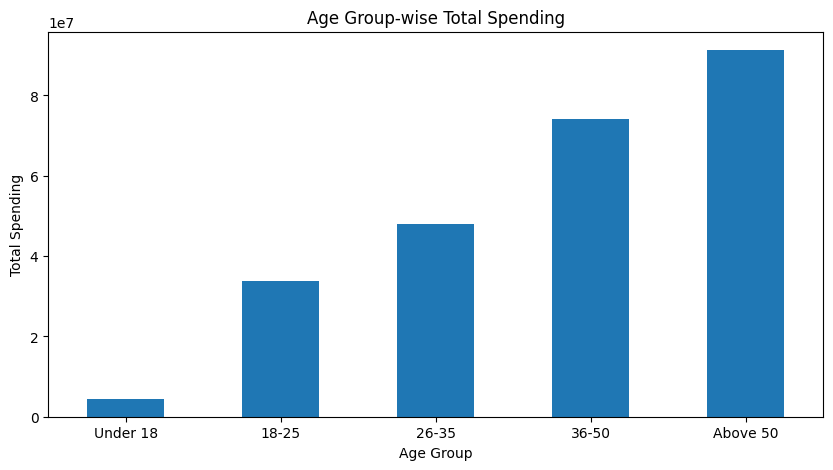

In [55]:
plt.figure(figsize=(10, 5))
age_spending.plot(kind="bar")
plt.title("Age Group-wise Total Spending")
plt.xlabel("Age Group")
plt.ylabel("Total Spending")
plt.xticks(rotation=0)
plt.show()

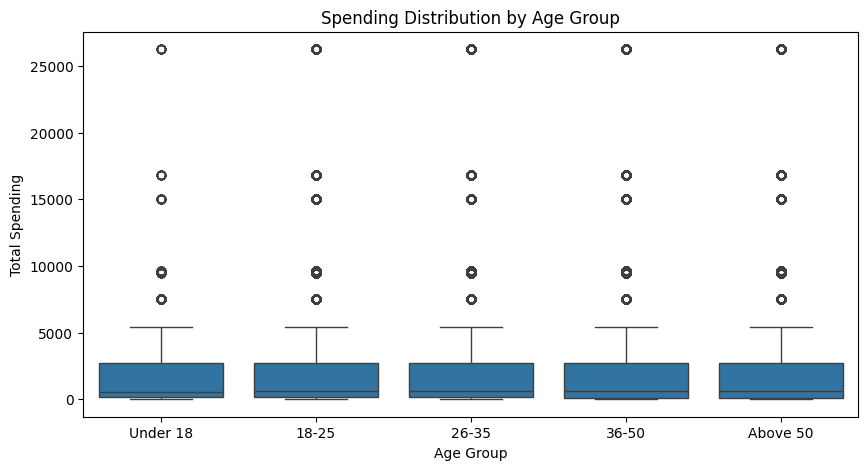

In [56]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="age_group",
    y="total_spending"
)
plt.title("Spending Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Spending")
plt.show()

In [57]:
# Monthly Spending Trend Analysis
df["month_name"] = df["invoice_date"].dt.month_name()

In [58]:
# Calculate monthly transaction count
monthly_count = df.groupby("month_name")["invoice_no"].count()
print(monthly_count)

month_name
April         7487
August        7635
December      7680
February     10482
January      11608
July          7877
June          7581
March         8730
May           7697
November      7563
October       7764
September     7353
Name: invoice_no, dtype: int64


In [59]:
# Calculate monthly total spending
monthly_spending = df.groupby("month_name")["total_spending"].sum()
print(monthly_spending)

month_name
April        18715685.98
August       19282361.29
December     19455085.64
February     26625090.10
January      28891525.59
July         20378722.63
June         18933775.30
March        21956191.33
May          19719331.10
November     18207139.95
October      20545090.43
September    18795794.91
Name: total_spending, dtype: float64


In [60]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]
monthly_spending = monthly_spending.reindex(month_order)
print(monthly_spending)

month_name
January      28891525.59
February     26625090.10
March        21956191.33
April        18715685.98
May          19719331.10
June         18933775.30
July         20378722.63
August       19282361.29
September    18795794.91
October      20545090.43
November     18207139.95
December     19455085.64
Name: total_spending, dtype: float64


In [62]:
# Calculate monthly average spending
monthly_average = df.groupby("month_name")["total_spending"].mean()
monthly_average = monthly_average.reindex(month_order)
print(monthly_average)

month_name
January      2488.932253
February     2540.077285
March        2515.027644
April        2499.757711
May          2561.950253
June         2497.530049
July         2587.117257
August       2525.522107
September    2556.207658
October      2646.199180
November     2407.396529
December     2533.214276
Name: total_spending, dtype: float64


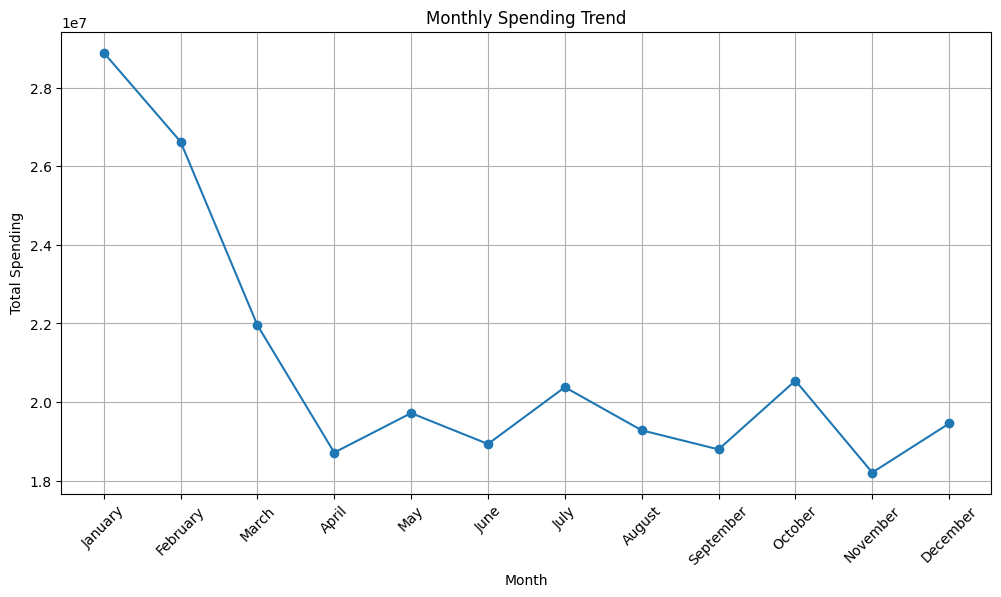

In [63]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_spending.index,
    monthly_spending.values,
    marker="o"
)

plt.title("Monthly Spending Trend")
plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.grid()

plt.show()

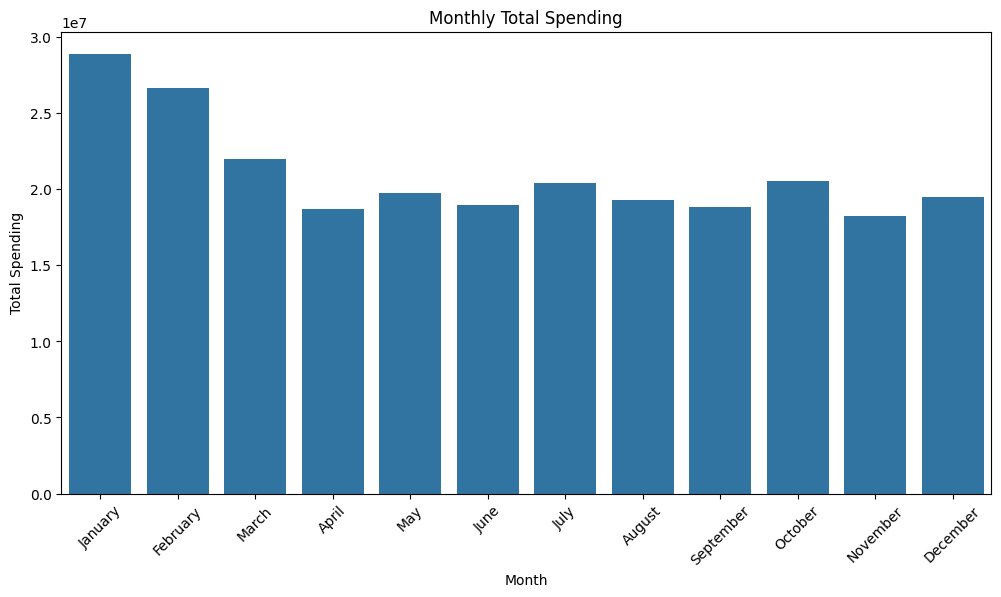

In [64]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_spending.index,
    y=monthly_spending.values
)

plt.title("Monthly Total Spending")
plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)

plt.show()

In [65]:
# Shopping Mall Performance Analysis
df["shopping_mall"].unique()

array(['Kanyon', 'Forum Istanbul', 'Metrocity', 'Metropol AVM',
       'Istinye Park', 'Mall of Istanbul', 'Emaar Square Mall',
       'Cevahir AVM', 'Viaport Outlet', 'Zorlu Center'], dtype=object)

In [66]:
# Count transactions by shopping mall
mall_count = df["shopping_mall"].value_counts()
print(mall_count)

shopping_mall
Mall of Istanbul     19943
Kanyon               19823
Metrocity            15011
Metropol AVM         10161
Istinye Park          9781
Zorlu Center          5075
Cevahir AVM           4991
Forum Istanbul        4947
Viaport Outlet        4914
Emaar Square Mall     4811
Name: count, dtype: int64


In [67]:
# Calculate total revenue by shopping mall
mall_revenue = df.groupby("shopping_mall")["total_spending"].sum().sort_values(ascending=False)
print(mall_revenue)

shopping_mall
Mall of Istanbul     50872481.68
Kanyon               50554231.10
Metrocity            37302787.33
Metropol AVM         25379913.19
Istinye Park         24618827.68
Zorlu Center         12901053.82
Cevahir AVM          12645138.20
Viaport Outlet       12521339.72
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Name: total_spending, dtype: float64


In [68]:
# Calculate average transaction value
mall_average = df.groupby("shopping_mall")["total_spending"].mean().sort_values(ascending=False)
print(mall_average)

shopping_mall
Emaar Square Mall    2578.694718
Mall of Istanbul     2550.894132
Kanyon               2550.281547
Viaport Outlet       2548.095181
Zorlu Center         2542.079570
Cevahir AVM          2533.588099
Istinye Park         2517.005181
Metropol AVM         2497.777108
Forum Istanbul       2487.148017
Metrocity            2485.030133
Name: total_spending, dtype: float64


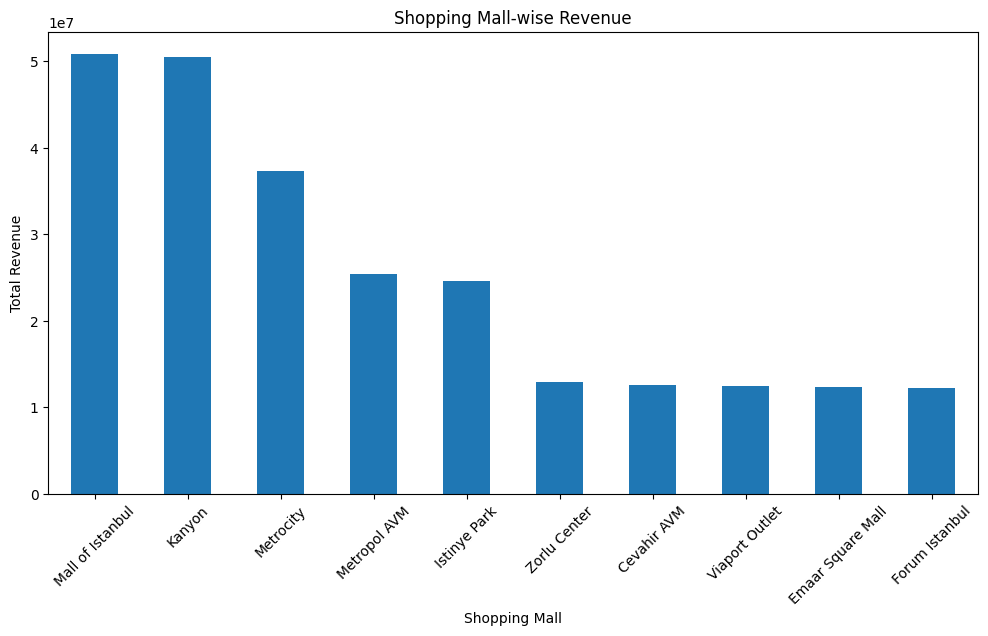

In [69]:
plt.figure(figsize=(12, 6))
mall_revenue.plot(kind="bar")
plt.title("Shopping Mall-wise Revenue")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

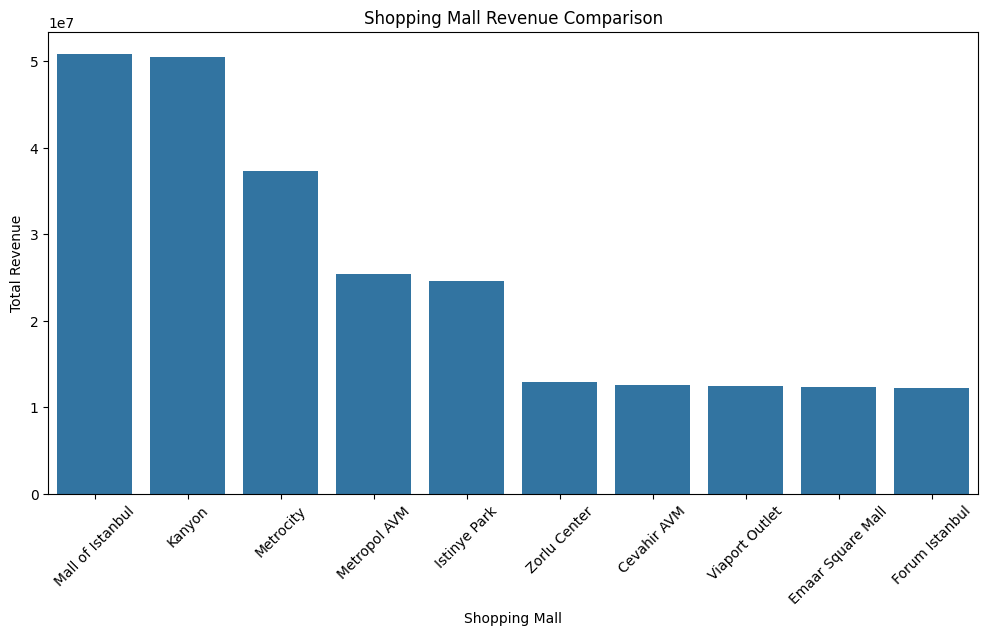

In [70]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=mall_revenue.index,
    y=mall_revenue.values
)
plt.title("Shopping Mall Revenue Comparison")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [71]:
# Find the top 5 shopping malls
top_5_malls = mall_revenue.head(5)
print(top_5_malls)

shopping_mall
Mall of Istanbul    50872481.68
Kanyon              50554231.10
Metrocity           37302787.33
Metropol AVM        25379913.19
Istinye Park        24618827.68
Name: total_spending, dtype: float64


In [72]:
# Select numerical columns
numerical_data = df[["age", "quantity", "price", "total_spending"]]

print(numerical_data.head())

   age  quantity    price  total_spending
0   28         5  1500.40         7502.00
1   21         3  1800.51         5401.53
2   20         1   300.08          300.08
3   66         5  3000.85        15004.25
4   53         4    60.60          242.40


In [73]:
# Calculate correlation using Pandas
correlation = numerical_data.corr()
print(correlation)

                     age  quantity     price  total_spending
age             1.000000  0.000667  0.001694        0.002731
quantity        0.000667  1.000000  0.344880        0.461173
price           0.001694  0.344880  1.000000        0.962372
total_spending  0.002731  0.461173  0.962372        1.000000


In [74]:
correlation_matrix = np.corrcoef(
    numerical_data.to_numpy(),
    rowvar=False
)
print(correlation_matrix)

[[1.00000000e+00 6.66645872e-04 1.69413386e-03 2.73105679e-03]
 [6.66645872e-04 1.00000000e+00 3.44879843e-01 4.61173258e-01]
 [1.69413386e-03 3.44879843e-01 1.00000000e+00 9.62372455e-01]
 [2.73105679e-03 4.61173258e-01 9.62372455e-01 1.00000000e+00]]


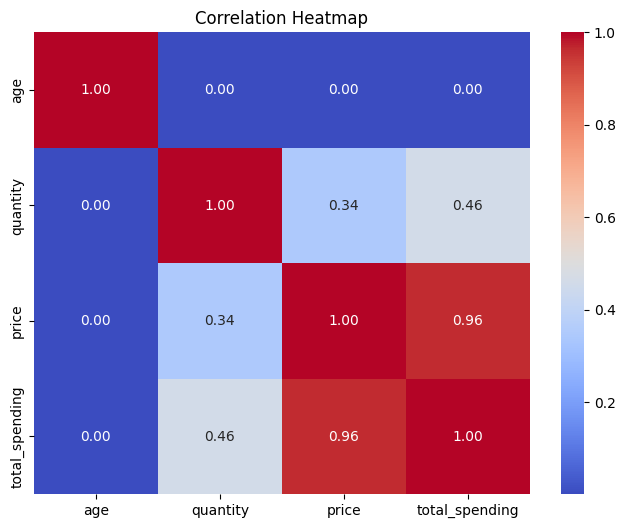

In [75]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

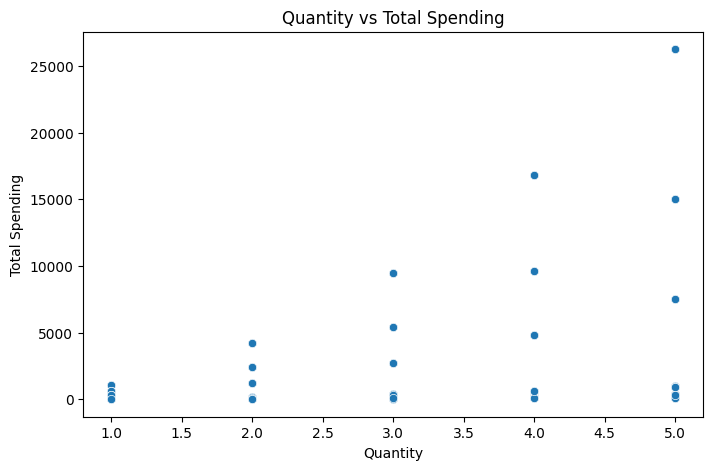

In [76]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="quantity",
    y="total_spending"
)
plt.title("Quantity vs Total Spending")
plt.xlabel("Quantity")
plt.ylabel("Total Spending")
plt.show()

In [77]:
spending = df["total_spending"].to_numpy()
Q1 = np.percentile(spending, 25)
Q3 = np.percentile(spending, 75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 136.35000000000002
Q3: 2700.7200000000003


In [78]:
IQR = Q3 - Q1
print("IQR:", IQR)

IQR: 2564.3700000000003


In [79]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -3710.2050000000004
Upper Limit: 6547.275000000001


In [80]:
outliers = df[
    (df["total_spending"] < lower_limit) |
    (df["total_spending"] > upper_limit)
]
print("Total Outliers:", len(outliers))

Total Outliers: 13986


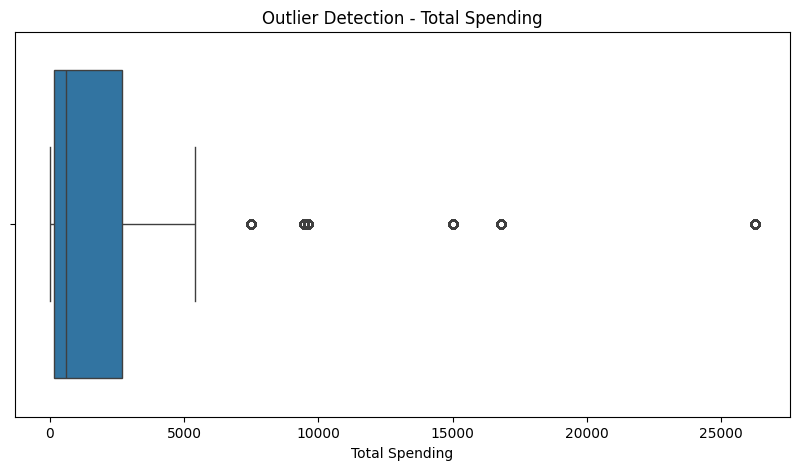

In [81]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["total_spending"])
plt.title("Outlier Detection - Total Spending")
plt.xlabel("Total Spending")
plt.show()

In [82]:
spending = df["total_spending"].to_numpy()

print("Mean:", np.mean(spending))
print("Median:", np.median(spending))
print("Standard Deviation:", np.std(spending))
print("Variance:", np.var(spending))

Mean: 2528.7892682264696
Median: 600.17
Standard Deviation: 4222.4545533468745
Variance: 17829122.455079757


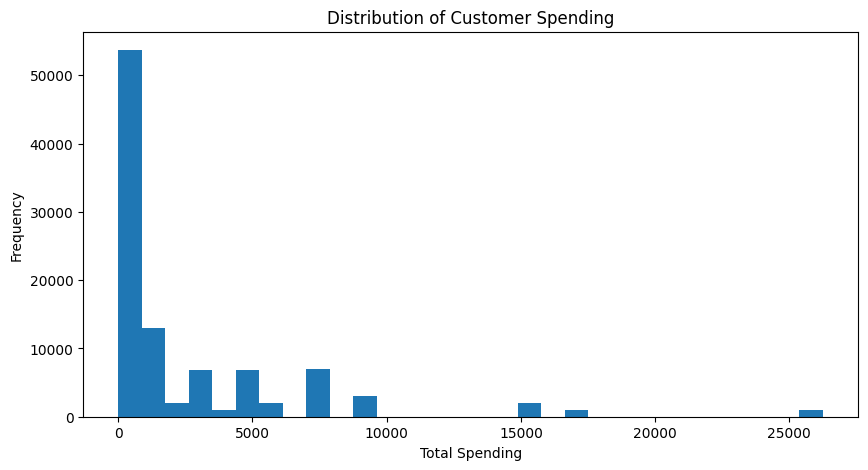

In [83]:
plt.figure(figsize=(10, 5))
plt.hist(df["total_spending"], bins=30)
plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Frequency")
plt.show()

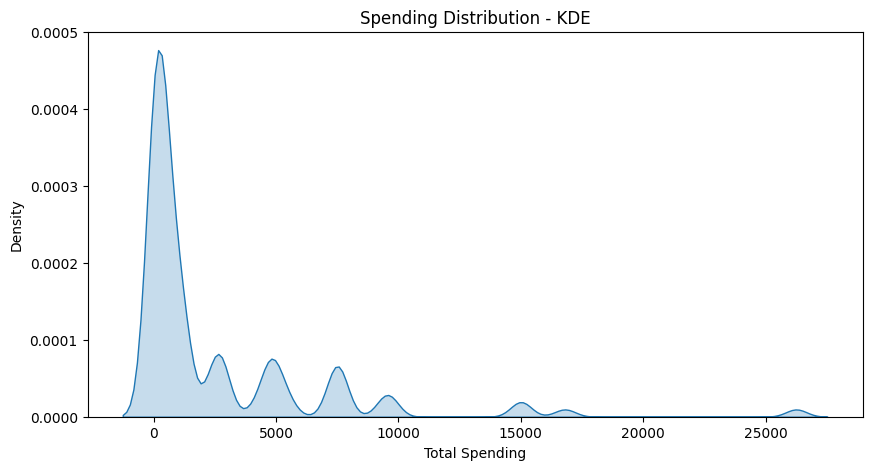

In [84]:
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df,
    x="total_spending",
    fill=True
)
plt.title("Spending Distribution - KDE")
plt.xlabel("Total Spending")
plt.show()

In [85]:
mean_value = np.mean(spending)
median_value = np.median(spending)
print("Mean:", mean_value)
print("Median:", median_value)

Mean: 2528.7892682264696
Median: 600.17


In [86]:
skewness = df["total_spending"].skew()
print("Skewness:", skewness)

Skewness: 2.871090417430552


In [87]:
spending = df["total_spending"].to_numpy()
mean = np.mean(spending)
std = np.std(spending)
skewness = np.mean(((spending - mean) / std) ** 3)
print("Skewness:", skewness)

Skewness: 2.871047115765828


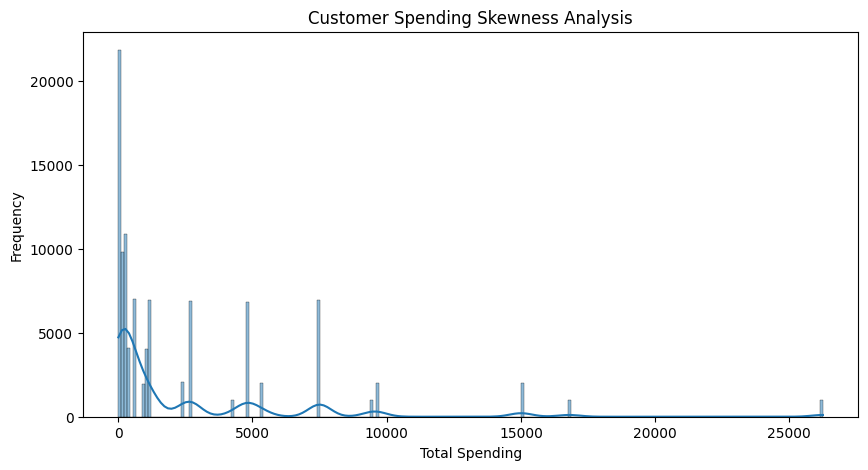

In [88]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="total_spending",
    kde=True
)
plt.title("Customer Spending Skewness Analysis")
plt.xlabel("Total Spending")
plt.ylabel("Frequency")
plt.show()

In [89]:
# Customer Spending Segmentation
customer_spending = df.groupby("customer_id")["total_spending"].sum()
print(customer_spending.head())

customer_id
C100004    7502.00
C100005    2400.68
C100006     322.56
C100012     130.75
C100019      35.84
Name: total_spending, dtype: float64


In [90]:
print("Minimum:", customer_spending.min())
print("Maximum:", customer_spending.max())
print("Average:", customer_spending.mean())
print("Median:", customer_spending.median())

Minimum: 5.23
Maximum: 26250.0
Average: 2528.7892682264696
Median: 600.17


In [91]:
customer_spending = customer_spending.to_frame()
customer_spending["spending_group"] = pd.qcut(
    customer_spending["total_spending"],
    q=3,
    labels=["Low", "Medium", "High"]
)
print(customer_spending.head(10))

             total_spending spending_group
customer_id                               
C100004             7502.00           High
C100005             2400.68           High
C100006              322.56         Medium
C100012              130.75            Low
C100019               35.84            Low
C100025              143.36            Low
C100028               15.15            Low
C100030             4801.28           High
C100034             1200.32         Medium
C100041             2700.72           High


In [92]:
# Count customers in each group
segment_count = customer_spending["spending_group"].value_counts()

print(segment_count)

spending_group
Low       33645
Medium    33015
High      32797
Name: count, dtype: int64


In [93]:
# Calculate revenue by customer segment
segment_revenue = customer_spending.groupby(
    "spending_group",
    observed=False
)["total_spending"].sum()
print(segment_revenue)

spending_group
Low       2.887660e+06
Medium    2.280159e+07
High      2.258165e+08
Name: total_spending, dtype: float64


In [94]:
# Calculate revenue contribution percentage
segment_percentage = (
    segment_revenue / np.sum(segment_revenue)
) * 100
print(segment_percentage)

spending_group
Low        1.148148
Medium     9.066031
High      89.785820
Name: total_spending, dtype: float64


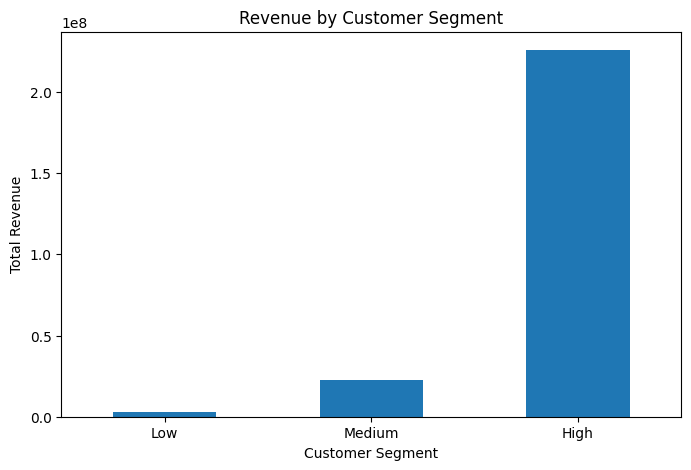

In [95]:
plt.figure(figsize=(8, 5))

segment_revenue.plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)

plt.show()

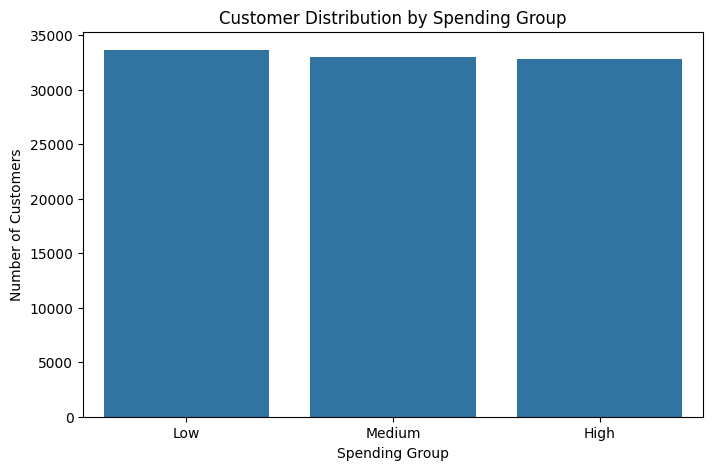

In [96]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=customer_spending,
    x="spending_group"
)
plt.title("Customer Distribution by Spending Group")
plt.xlabel("Spending Group")
plt.ylabel("Number of Customers")
plt.show()

In [97]:
# Top 10 Customers Analysis
customer_spending = df.groupby("customer_id")["total_spending"].sum()
print(customer_spending.head())

customer_id
C100004    7502.00
C100005    2400.68
C100006     322.56
C100012     130.75
C100019      35.84
Name: total_spending, dtype: float64


In [98]:
# Find the top 10 customers
top_10_customers = customer_spending.sort_values(
    ascending=False
).head(10)
print(top_10_customers)

customer_id
C255975    26250.0
C219246    26250.0
C471560    26250.0
C477683    26250.0
C476770    26250.0
C100322    26250.0
C176113    26250.0
C276116    26250.0
C472297    26250.0
C162292    26250.0
Name: total_spending, dtype: float64


In [99]:
# Calculate their percentage contribution
total_revenue = np.sum(df["total_spending"])
top_10_percentage = (
    np.sum(top_10_customers) / total_revenue
) * 100
print("Top 10 Customer Contribution:", top_10_percentage, "%")

Top 10 Customer Contribution: 0.10437135286794691 %


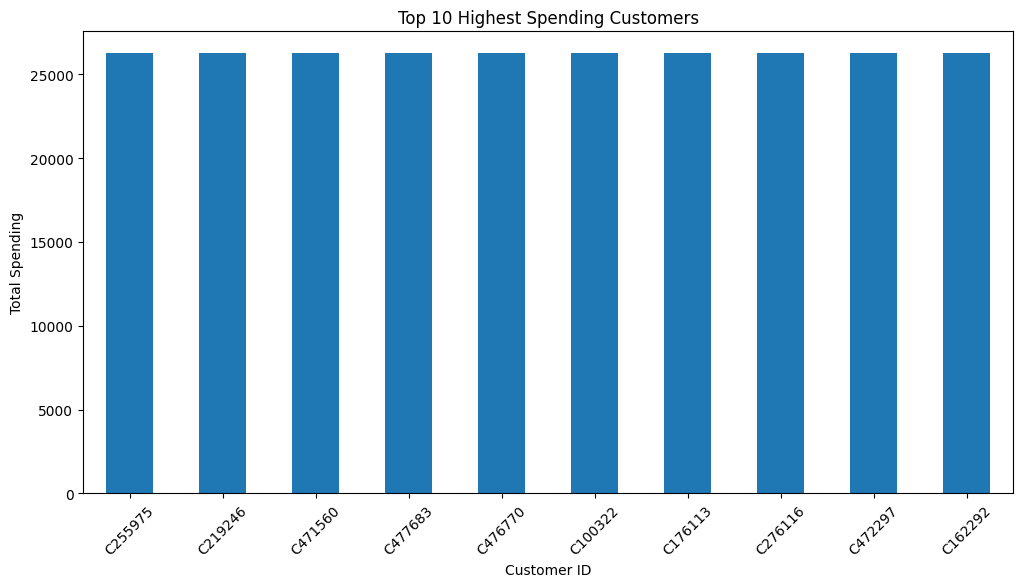

In [100]:
plt.figure(figsize=(12, 6))
top_10_customers.plot(kind="bar")
plt.title("Top 10 Highest Spending Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

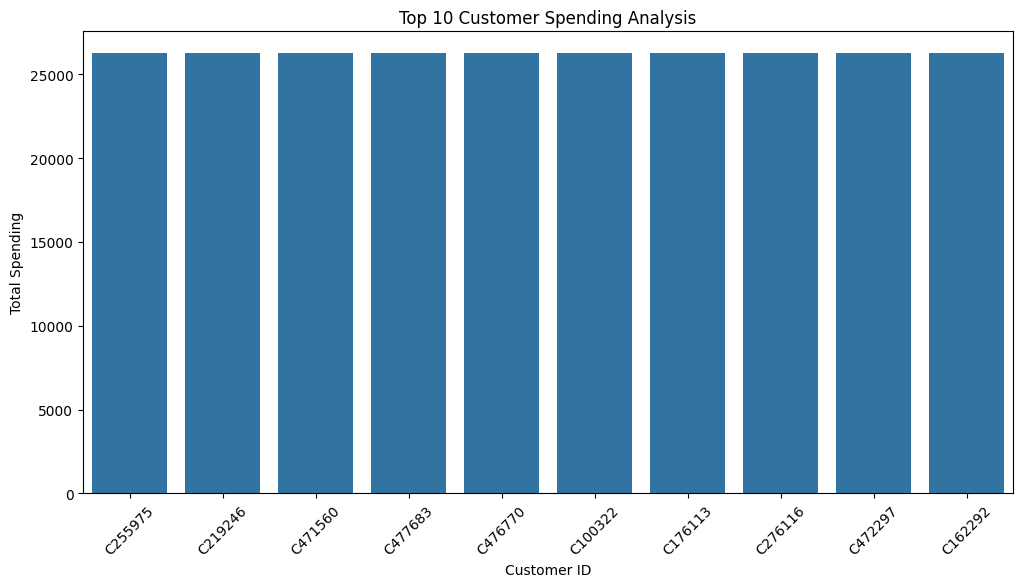

In [101]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_10_customers.index.astype(str),
    y=top_10_customers.values
)
plt.title("Top 10 Customer Spending Analysis")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

In [102]:
# Product Category Performance Analysis
category_quantity = df.groupby("category")["quantity"].sum().sort_values(ascending=False)
print(category_quantity)

category
Clothing           103558
Cosmetics           45465
Food & Beverage     44277
Toys                30321
Shoes               30217
Technology          15021
Books               14982
Souvenir            14871
Name: quantity, dtype: int64


In [103]:
# Calculate average product price by category
category_price = df.groupby("category")["price"].mean().sort_values(ascending=False)
print(category_price)

category
Technology         3156.935548
Shoes              1807.388568
Clothing            901.084021
Cosmetics           122.448626
Toys                107.733185
Books                45.568621
Souvenir             34.894345
Food & Beverage      15.671948
Name: price, dtype: float64


In [104]:
# Calculate total revenue by category
category_revenue = df.groupby("category")["total_spending"].sum().sort_values(ascending=False)
print(category_revenue)

category
Clothing           1.139968e+08
Shoes              6.655345e+07
Technology         5.786235e+07
Cosmetics          6.792863e+06
Toys               3.980426e+06
Food & Beverage    8.495351e+05
Books              8.345529e+05
Souvenir           6.358247e+05
Name: total_spending, dtype: float64


In [105]:
# Find the top 5 categories by revenue
top_5_categories = category_revenue.head(5)
print(top_5_categories)

category
Clothing      1.139968e+08
Shoes         6.655345e+07
Technology    5.786235e+07
Cosmetics     6.792863e+06
Toys          3.980426e+06
Name: total_spending, dtype: float64


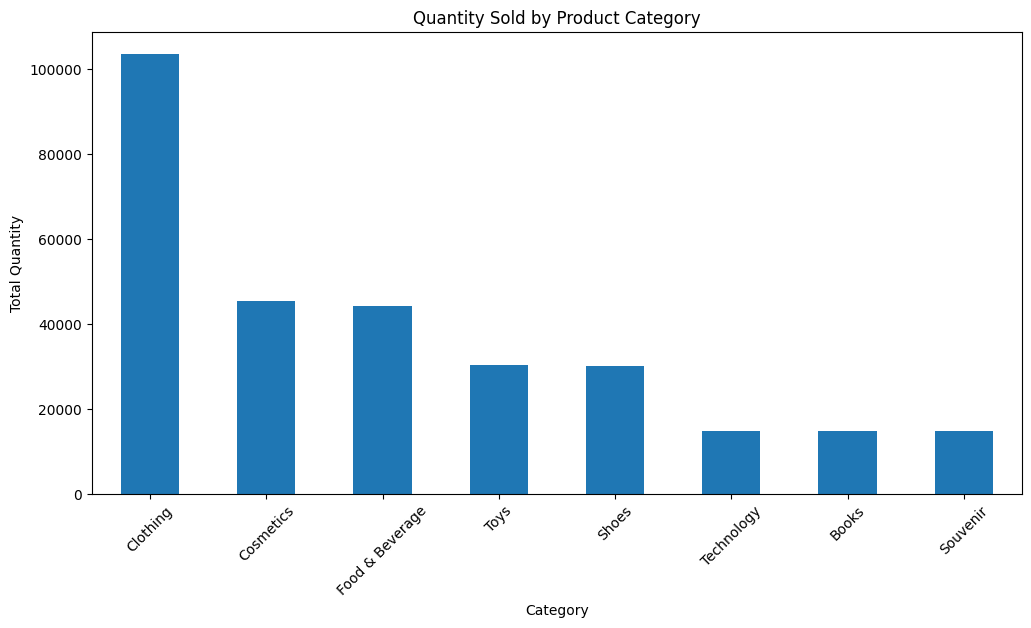

In [106]:
plt.figure(figsize=(12, 6))
category_quantity.plot(kind="bar")
plt.title("Quantity Sold by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)
plt.show()

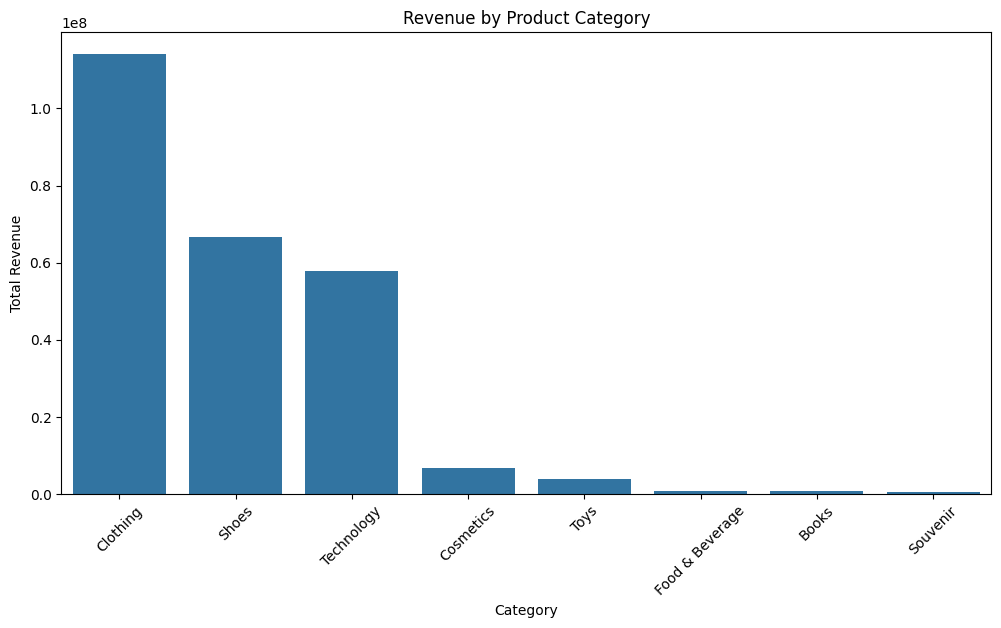

In [107]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [108]:
# Calculate revenue contribution percentage
category_percentage = (
    category_revenue / np.sum(category_revenue)
) * 100
print(category_percentage)

category
Clothing           45.325712
Shoes              26.461995
Technology         23.006369
Cosmetics           2.700877
Toys                1.582638
Food & Beverage     0.337780
Books               0.331823
Souvenir            0.252807
Name: total_spending, dtype: float64


In [109]:
# Quantity and Price Analysis
quantity = df["quantity"].to_numpy()

print("Mean Quantity:", np.mean(quantity))
print("Median Quantity:", np.median(quantity))
print("Minimum Quantity:", np.min(quantity))
print("Maximum Quantity:", np.max(quantity))

Mean Quantity: 3.003428617392441
Median Quantity: 3.0
Minimum Quantity: 1
Maximum Quantity: 5


In [110]:
price = df["price"].to_numpy()

print("Mean Price:", np.mean(price))
print("Median Price:", np.median(price))
print("Minimum Price:", np.min(price))
print("Maximum Price:", np.max(price))

Mean Price: 689.2563209226097
Median Price: 203.3
Minimum Price: 5.23
Maximum Price: 5250.0


In [111]:
# Calculate quantity-wise revenue
quantity_revenue = df.groupby("quantity")["total_spending"].sum()
print(quantity_revenue)

quantity
1    4.489553e+06
2    1.838412e+07
3    4.123262e+07
4    7.291295e+07
5    1.144866e+08
Name: total_spending, dtype: float64


In [112]:
# Analyze price vs quantity
price_quantity = df.groupby("quantity")["price"].mean()
print(price_quantity)

quantity
1     227.123653
2     463.589752
3     682.128448
4     924.212205
5    1145.438302
Name: price, dtype: float64


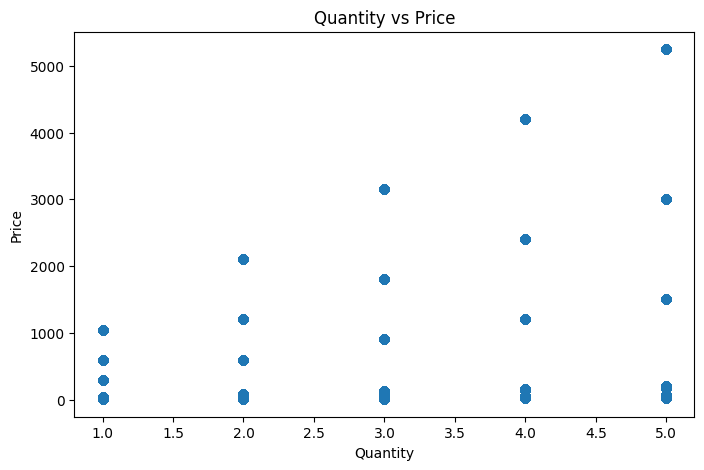

In [113]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["quantity"],
    df["price"]
)
plt.title("Quantity vs Price")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.show()

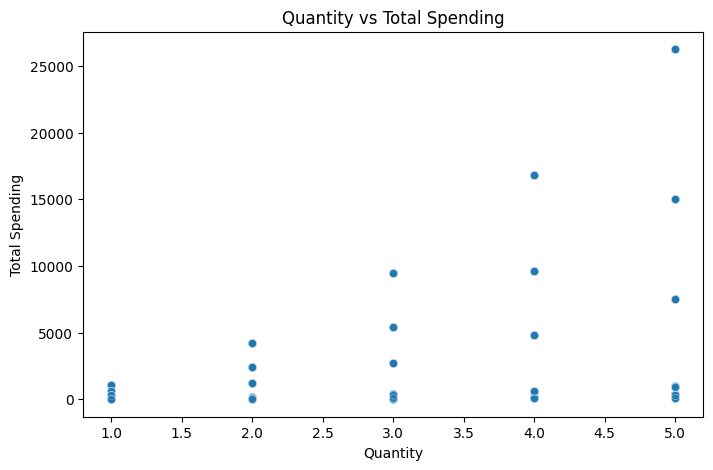

In [114]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="quantity",
    y="total_spending",
    alpha=0.5
)

plt.title("Quantity vs Total Spending")
plt.xlabel("Quantity")
plt.ylabel("Total Spending")

plt.show()

In [115]:
correlation = np.corrcoef(
    df["quantity"],
    df["price"]
)[0, 1]
print("Quantity and Price Correlation:", correlation)

Quantity and Price Correlation: 0.3448798427911956


In [116]:
# Advanced Statistical Analysis
# Calculate percentiles using NumPy
spending = df["total_spending"].to_numpy()

print("25th Percentile:", np.percentile(spending, 25))
print("50th Percentile:", np.percentile(spending, 50))
print("75th Percentile:", np.percentile(spending, 75))
print("90th Percentile:", np.percentile(spending, 90))
print("95th Percentile:", np.percentile(spending, 95))

25th Percentile: 136.35000000000002
50th Percentile: 600.17
75th Percentile: 2700.7200000000003
90th Percentile: 7502.0
95th Percentile: 9602.72


In [117]:
variance = np.var(spending)
print("Variance:", variance)

Variance: 17829122.455079757


In [118]:
std = np.std(spending)
print("Standard Deviation:", std)

Standard Deviation: 4222.4545533468745


In [119]:
# Calculate coefficient of variation (CV)
mean = np.mean(spending)
std = np.std(spending)
cv = (std / mean) * 100
print("Coefficient of Variation:", cv, "%")

Coefficient of Variation: 166.97534295960662 %


In [120]:
# Compare spending across genders
gender_stats = df.groupby("gender")["total_spending"].agg(
    ["mean", "median", "std", "min", "max"]
)
print(gender_stats)

               mean  median          std   min      max
gender                                                 
Female  2525.253623  600.17  4226.617822  5.23  26250.0
Male    2534.050237  600.17  4216.352329  5.23  26250.0


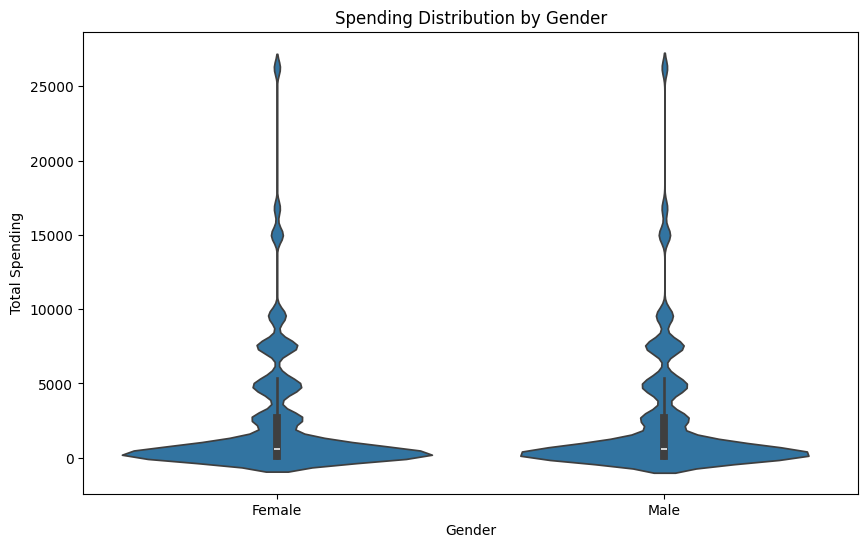

In [121]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="gender",
    y="total_spending"
)

plt.title("Spending Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Spending")

plt.show()

In [122]:
# Final EDA Visualization Dashboard
category_revenue = df.groupby("category")["total_spending"].sum()
payment_count = df["payment_method"].value_counts()
gender_spending = df.groupby("gender")["total_spending"].sum()
monthly_spending = df.groupby(
    df["invoice_date"].dt.month
)["total_spending"].sum()
mall_revenue = df.groupby("shopping_mall")["total_spending"].sum()
age_spending = df.groupby("age_group")["total_spending"].sum()

/tmp/ipykernel_15020/2020084741.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_spending = df.groupby("age_group")["total_spending"].sum()


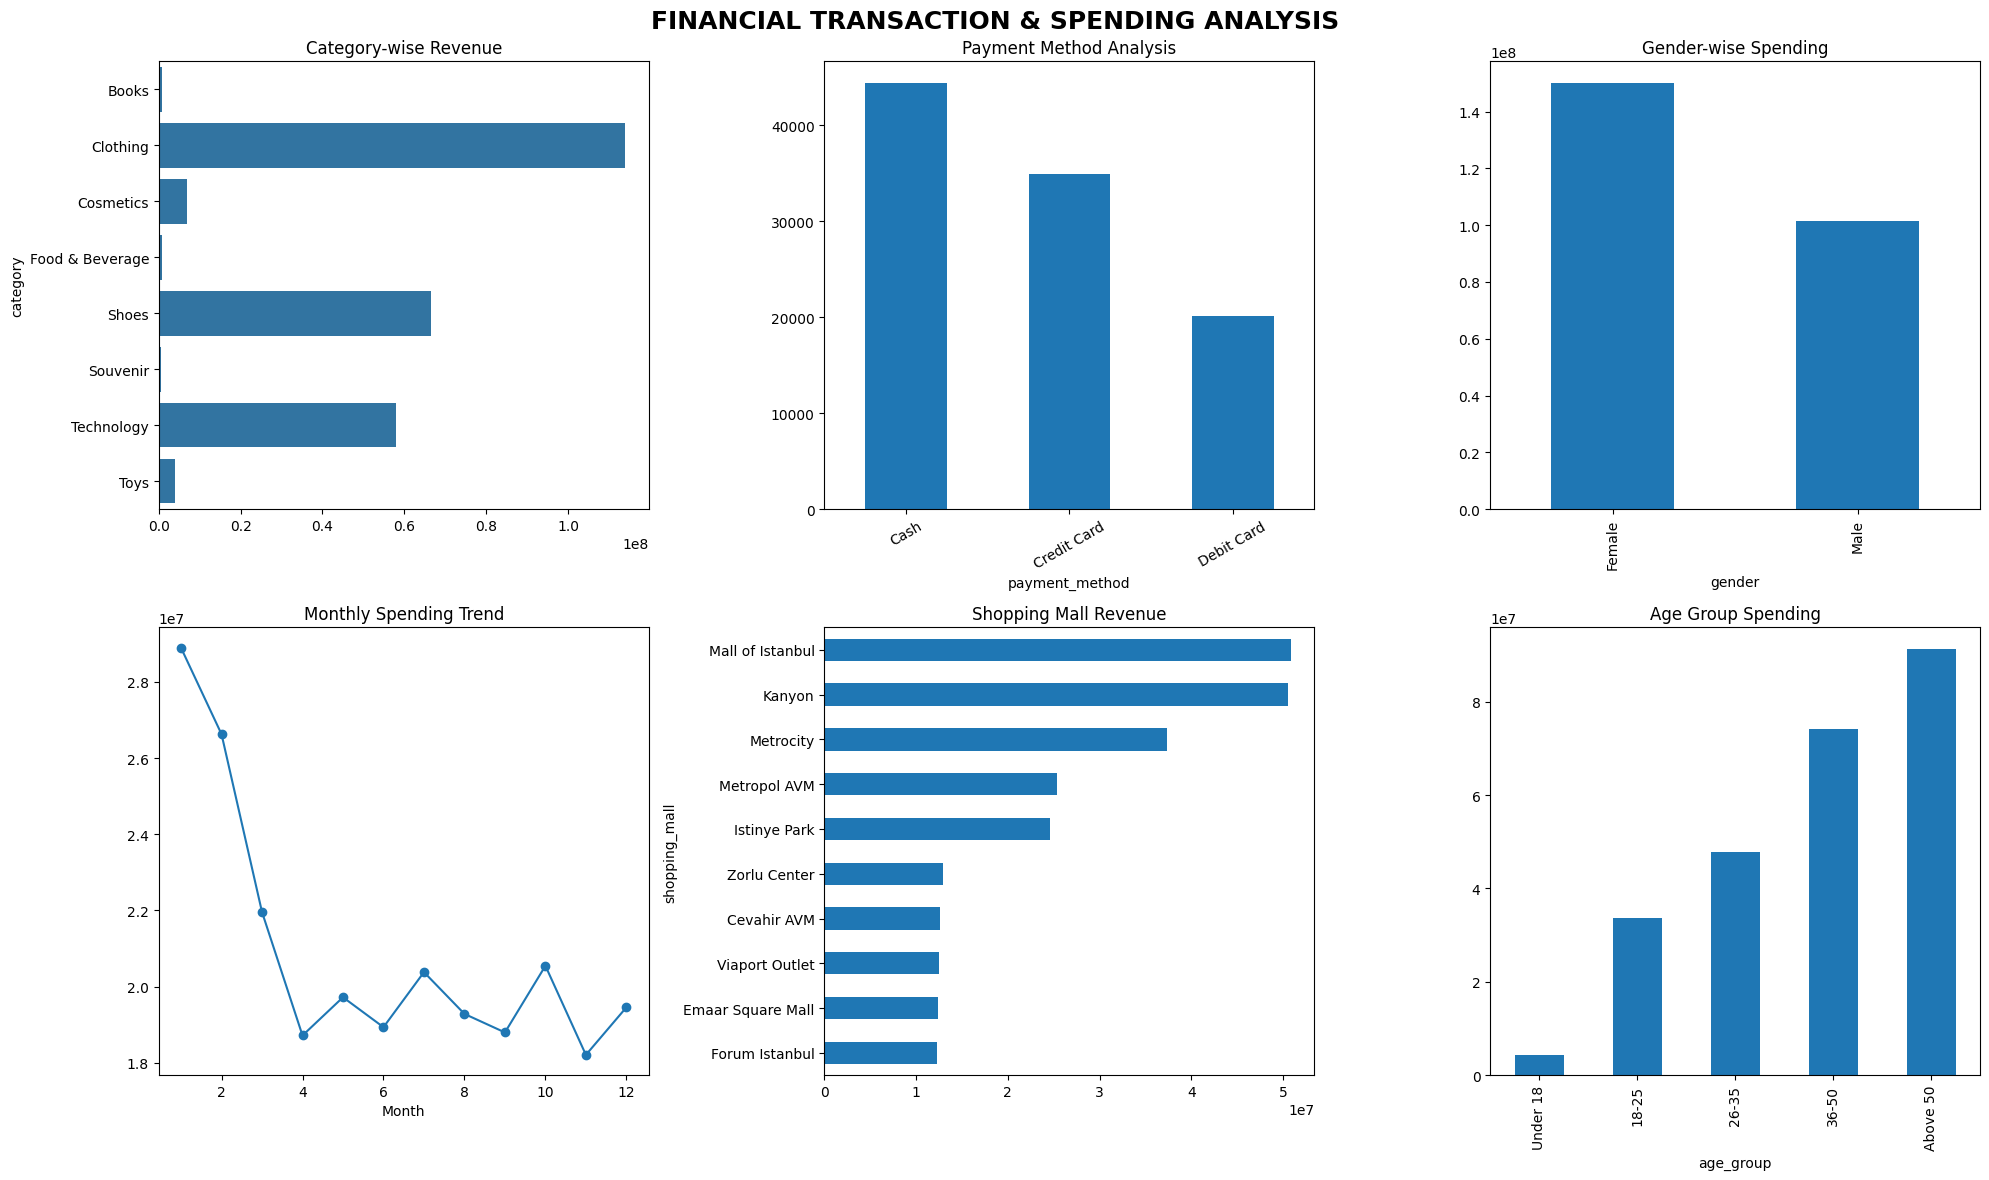

In [123]:

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle(
    "FINANCIAL TRANSACTION & SPENDING ANALYSIS",
    fontsize=18,
    fontweight="bold"
)
# 1. Category-wise Revenue
sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Category-wise Revenue")
# 2. Payment Method
payment_count.plot(
    kind="bar",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Payment Method Analysis")
axes[0, 1].tick_params(axis="x", rotation=30)
# 3. Gender-wise Spending
gender_spending.plot(
    kind="bar",
    ax=axes[0, 2]
)
axes[0, 2].set_title("Gender-wise Spending")
# 4. Monthly Spending Trend
axes[1, 0].plot(
    monthly_spending.index,
    monthly_spending.values,
    marker="o"
)
axes[1, 0].set_title("Monthly Spending Trend")
axes[1, 0].set_xlabel("Month")
# 5. Mall Revenue
mall_revenue.sort_values().plot(
    kind="barh",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Shopping Mall Revenue")
# 6. Age Group Spending
age_spending.plot(
    kind="bar",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Age Group Spending")
plt.tight_layout()
plt.show()


In [124]:
# Key Performance Metrics

total_revenue = df["total_spending"].sum()
total_transactions = len(df)
total_customers = df["customer_id"].nunique()
average_spending = df["total_spending"].mean()

highest_category = category_revenue.idxmax()
highest_payment = df.groupby("payment_method")["total_spending"].sum().idxmax()
highest_mall = mall_revenue.idxmax()
highest_gender = gender_spending.idxmax()
highest_age_group = age_spending.idxmax()

print("FINANCIAL ANALYSIS SUMMARY")
print("--------------------------")

print("Total Revenue:", round(total_revenue, 2))
print("Total Transactions:", total_transactions)
print("Unique Customers:", total_customers)
print("Average Transaction Value:", round(average_spending, 2))

print("\nBUSINESS INSIGHTS")
print("--------------------------")

print("Top Revenue Category:", highest_category)
print("Most Profitable Payment Method:", highest_payment)
print("Top Performing Mall:", highest_mall)
print("Highest Spending Gender:", highest_gender)
print("Highest Spending Age Group:", highest_age_group)

FINANCIAL ANALYSIS SUMMARY
--------------------------
Total Revenue: 251505794.25
Total Transactions: 99457
Unique Customers: 99457
Average Transaction Value: 2528.79

BUSINESS INSIGHTS
--------------------------
Top Revenue Category: Clothing
Most Profitable Payment Method: Cash
Top Performing Mall: Mall of Istanbul
Highest Spending Gender: Female
Highest Spending Age Group: Above 50


In [126]:
fig.savefig(
    "financial_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

In [127]:
from google.colab import files

files.download("financial_analysis_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>